In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import os

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Regresion_logistica_con_sklearn/")

In [2]:
df = pd.read_csv("churn_dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info() #La variable TotalCharges se muestra como object, cuando es numerica. Hay que arreglarlo
df.TotalCharges= pd.to_numeric(df.TotalCharges, errors= "coerce")

df.isnull().sum() #Revisar si hay valores nulos
df.dropna(inplace= True) #Eliminar datos nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.drop("customerID", axis= 1, inplace= True) #Eliminar la columna ID que no aporta en el analisis

In [ ]:
#Convertir a numero la variable objetivo = Churn
df["Churn"].replace(to_replace= "Yes", value= 1, inplace= True) 
df["Churn"].replace(to_replace= "No", value= 0, inplace= True)

In [6]:
df_processing= df.copy() #Crear una copia del df

In [7]:
#ONE HOT ENCODING PARA TRANSFORMAR LAS VARIABLES CATEGORICAS EN NUMERICAS
df_processing = pd.get_dummies(df_processing) #Cuando existe la variable categorica, marca 1, de lo contrario, marca 0
df_processing.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,True,False,False,True,True,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,1889.50,0,False,True,True,False,True,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,False,True,True,False,True,...,False,True,False,False,False,True,False,False,False,True
3,0,45,42.30,1840.75,0,False,True,True,False,True,...,False,False,True,False,True,False,True,False,False,False
4,0,2,70.70,151.65,1,True,False,True,False,True,...,False,True,False,False,False,True,False,False,True,False


In [ ]:
#ANALISIS DE CORRELACION Y ESCALABILIDAD DE LOS DATOS
fig= plt.figure(figsize= (15,9))
df_processing.corr()["Churn"].sort_values(ascending= True).plot(kind="bar") #Analisis de correlacion con la variable Churn


In [8]:
#ESCALAR LOS DATOS

scaler= MinMaxScaler() #Llevar los datos a una misma escala
df_processing_scaled= scaler.fit_transform(df_processing)
df_processing_scaled= pd.DataFrame(df_processing_scaled) #Convertir a df
df_processing_scaled.columns= df_processing.columns #Recuperar los nombres de las columnas
df_processing_scaled.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,0.000000,0.115423,0.001275,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.464789,0.385075,0.215867,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.014085,0.354229,0.010310,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,0.619718,0.239303,0.210241,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.014085,0.521891,0.015330,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [ ]:
sns.countplot(data= df, x="gender", hue= "Churn")

In [30]:
def plot_categorical(column):
    fig= plt.figure(figsize= (6,6))
    sns.countplot(data= df, x= column, hue= "Churn")

In [ ]:
columns_categorical= df.select_dtypes(include= "object").columns

for i in columns_categorical:
    plot_categorical(i)

In [ ]:
fig= plt.figure(figsize=(10,10))
sns.pairplot(data= df, hue= "Churn")

In [20]:
#CREAR EL MODELO

X= df_processing_scaled.drop("Churn", axis=1)
y= df_processing_scaled["Churn"].values

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

model= LogisticRegression()
result= model.fit(X_train, y_train)

predictions= model.predict(X_test)

metrics_model= metrics.accuracy_score(y_test, predictions)
print("Model accuracy:", round(metrics_model,3))

Model accuracy: 0.795


Axes(0.125,0.11;0.775x0.77)


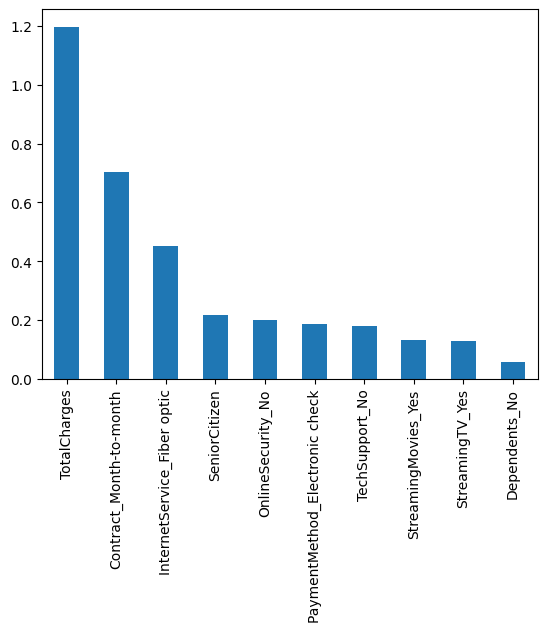

In [25]:
#EVALUACION DEL MODELO

model.predict_proba(X_test) #Devuelve la probabilidad de que cada instancia en el conjunto de prueba pertenezca a cada una de las clases posibles.
# La primera columna representa la probabilidad de que la instancia pertenezca a la clase negativa (clase 0) 
# La segunda columna representa la probabilidad de que pertenezca a la clase positiva (clase 1)
model.coef_
#Los resultados positivos indican las categorias con importancia para predecir cuando la clase positiva
#Los resultados negativos indican las categorias con importancia para predecir cuando la clase negativa

model.feature_names_in_

weights= pd.Series(model.coef_[0], index= X.columns.values)

#Seleccionar los 10 pesos mas grandes del modelo que predicen cuando el estado es positivo  y graficarlos
print(weights.sort_values(ascending= False)[:10].plot(kind="bar")) 

Axes(0.125,0.11;0.775x0.77)


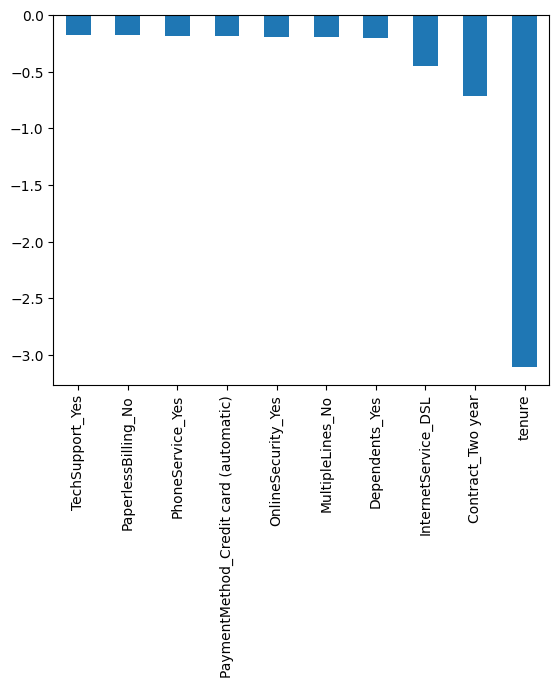

In [26]:
#Seleccionar los 10 pesos mas grandes del modelo que predicen cuando el estado es negativo  y graficarlos
print(weights.sort_values(ascending= False)[-10:].plot(kind="bar")) 

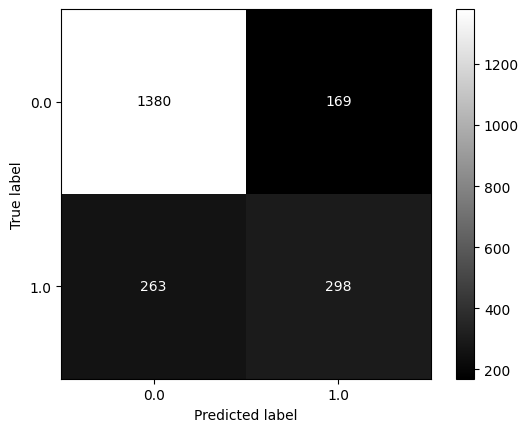

In [28]:
cm = confusion_matrix(y_test, predictions, labels= model.classes_)
disp= ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= model.classes_)
disp.plot(cmap="gray")